# SBI Loan-Default Early Warning — Full Pipeline

**Data cleaning:** unchanged from the original SBI notebook (same rules, same thresholds, same column lists).
**Everything after cleaning:** the IDFC pipeline structure — imputation safety net, scaling, PCA,
duplicate removal, stratified split, undersample + SMOTE, a model zoo, Optuna tuning,
soft-voting and stacking ensembles, RFE and genetic feature selection, threshold tuning,
calibration, and a submission file.

Every expensive step is **checkpointed**: it computes once, writes to `artifacts/`, and is
loaded from disk on every later run. You can stop the kernel at any point and pick up where
you left off. Set `FORCE_RERUN = True` in the config cell to recompute from scratch.

---
### Read this before you run


1. **Scaler and PCA are fitted after the train/test split, on the training fold only.
2. **`RandomUnderSampler(sampling_strategy=0.07)` cannot run on this dataset.** That parameter is
   minority/majority *after* undersampling, and your raw ratio is already ~0.12, so 0.07 asks for
   more majority rows than exist. The config uses 0.20 and the code checks the ratio is legal
   before calling.
3. **`GridSearchCV` over 81 RF combinations and `StratifiedKFold(n_splits=100)` are replaced** with
   `RandomizedSearchCV` and 5-fold. On 200k rows the originals are days of compute, not hours.
   The knobs are all in the config cell — raise them when you have the machine for it.

One judgement call left to you: `USE_PCA`. It defaults to `True`.
But PCA on 138 features usually *hurts* gradient boosting, and it destroys per-feature SHAP —
which matters if you ever have to explain a specific decline. Run both and compare the leaderboard.


In [25]:
!pip install -U catboost

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.8/100.2 MB 3.0 MB/s eta 0:00:33
    --------------------------------------- 1.3/100.2 MB 2.8 MB/s eta 0:00:36
    --------------------------------------- 1.8/100.2 MB 3.0 MB/s eta 0:00:33
   - -------------------------------------- 2.6/100.2 MB 3.1 MB/s eta 0:00:32
   - -------------------------------------- 3.4/100.2 MB 3.1 MB/s eta 0:00:32
   - -------------------------------------- 3.9/100.2 MB 3.1 MB/s eta 0:00:32
   - -------------------------------------- 4.7/100.2 MB 3.0 MB/s eta 0:00:32
   -- ------------------------------------- 5.2/100.2 MB 3.1 MB/s eta 0:00:31
   -- ------------------------------------- 6.3/100.2 MB 3.2 MB/s eta 0:00:30
   -- ------------------------------------- 6.6/100.2 MB 3.2 MB/s eta 0:00:30
   -- ------------------------------------- 7.3/100.2 MB 3.1 MB/s eta 0:00:30


  You can safely remove it manually.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from catboost import CatBoostClassifier
print(hasattr(CatBoostClassifier, "__sklearn_tags__"))   # want True

True


## 0. Configuration

Edit this cell, then run the notebook top to bottom.

In [1]:
# =====================================================================
# 0. CONFIGURATION
# =====================================================================
import os

# ---- paths ----------------------------------------------------------
TRAIN_PATH = "HACKATHON_TRAINING_DATA.CSV"
PRED_PATH  = "HACKATHON_PREDICTION_DATA.CSV"
ART_DIR    = "artifacts"

TARGET_COL   = "TARGET"
RANDOM_STATE = 42

# ---- feature space --------------------------------------------------
USE_PCA      = False     
PCA_VARIANCE = 0.90     # retain this much explained variance

# ---- split / resampling ---------------------------------------------
TEST_SIZE         = 0.20
UNDERSAMPLE_RATIO = 0.20   # minority/majority AFTER undersampling. Must be > the raw ratio (~0.12).
SMOTE_RATIO       = 0.50   # minority/majority AFTER SMOTE. Must be > UNDERSAMPLE_RATIO.

# ---- runtime knobs --------------------------------------------------
HEAVY_MODEL_CAP      = 15_000  # rows used to fit SVC / KNN (both roughly O(n^2) — raise slowly)
TUNING_CAP           = 80_000  # rows used inside each Optuna / RandomizedSearch trial
N_OPTUNA_TRIALS      = 20
N_RANDOM_SEARCH      = 8

# Random Forest size caps. Unbounded trees on 3 lakh rows produce multi-GB pickles
# and will OOM a 12 GB Colab box. These bounds cost almost no AUC.
RF_N_ESTIMATORS = 200
RF_MAX_DEPTH    = 18
RF_MIN_LEAF     = 20
ENSEMBLE_CV_FOLDS    = 5      
TOP_TRIALS_PER_MODEL = 3       # Optuna trials per family feeding the big voting ensemble

# ---- optional / slow stages -----------------------------------------
RUN_SVC = True
RUN_KNN = True
RUN_GA  = False   # DEAP genetic feature selection — slowest stage here
RUN_NN  = False   # your original Keras net, kept as an optional extra model

# ---- checkpointing --------------------------------------------------
FORCE_RERUN = False   # True = ignore saved artifacts, recompute everything

os.makedirs(ART_DIR, exist_ok=True)
print("Config loaded. Artifacts ->", os.path.abspath(ART_DIR))

Config loaded. Artifacts -> C:\Users\vansh\PSB Hacakthon\Placements Prep\artifacts


## 1. Install and import

Uncomment the pip line the first time you run this on a fresh machine.

In [3]:
# !pip install -q pandas numpy scikit-learn lightgbm xgboost catboost imbalanced-learn optuna deap joblib matplotlib seaborn
# !pip install -q scikeras[tensorflow]     # only needed if RUN_NN = True

In [4]:
# =====================================================================
# 1. IMPORTS
# =====================================================================
import re, json, time, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, VotingClassifier,
                              StackingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import RFE
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_curve,
                             precision_recall_curve, classification_report,
                             confusion_matrix, brier_score_loss)

warnings.filterwarnings("ignore")
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)

# optional dependencies — the notebook degrades gracefully if any are missing
def _try(name):
    try:
        return __import__(name)
    except Exception:
        print(f"  [warn] {name} not installed — stages using it will be skipped")
        return None

lgb      = _try("lightgbm")
xgboost  = _try("xgboost")
catboost = _try("catboost")
optuna   = _try("optuna")

try:
    from imblearn.under_sampling import RandomUnderSampler
    from imblearn.over_sampling import SMOTE
    HAS_IMBLEARN = True
except Exception:
    HAS_IMBLEARN = False
    print("  [warn] imbalanced-learn not installed — resampling will be skipped")

HAS_LGB, HAS_XGB = lgb is not None, xgboost is not None
HAS_CAT, HAS_OPTUNA = catboost is not None, optuna is not None
if HAS_LGB:     from lightgbm import LGBMClassifier
if HAS_XGB:     from xgboost import XGBClassifier
if HAS_CAT:     from catboost import CatBoostClassifier
if HAS_OPTUNA:  optuna.logging.set_verbosity(optuna.logging.WARNING)

print("imports ok |", f"lgb={HAS_LGB} xgb={HAS_XGB} catboost={HAS_CAT} optuna={HAS_OPTUNA} imblearn={HAS_IMBLEARN}")

  [warn] imbalanced-learn not installed — resampling will be skipped
imports ok | lgb=True xgb=True catboost=True optuna=True imblearn=False


## 2. Checkpoint helpers

`checkpoint(name, fn)` runs `fn()` once, writes the result to `artifacts/name`, and on every
later run loads it back instead of recomputing. Fitted scalers, PCA rotations, tuned parameter
sets, and trained models all go through it, so a second pass over the notebook is fast.

In [5]:
# =====================================================================
# 2. CHECKPOINTING
# =====================================================================
def art(name):        return os.path.join(ART_DIR, name)
def art_exists(name): return os.path.exists(art(name)) and not FORCE_RERUN

def save_art(obj, name):
    joblib.dump(obj, art(name))
    size = os.path.getsize(art(name)) / 1e6
    print(f"   saved -> {art(name)}  ({size:,.1f} MB)")
    return obj

def load_art(name):
    print(f"   loaded <- {art(name)}")
    return joblib.load(art(name))

def checkpoint(name, fn, *args, **kwargs):
    """Compute once, cache to disk, reuse forever (until FORCE_RERUN)."""
    if art_exists(name):
        print(f"[checkpoint] {name} already exists — skipping compute")
        return load_art(name)
    print(f"[checkpoint] computing {name} ...")
    t0 = time.time()
    obj = fn(*args, **kwargs)
    print(f"[checkpoint] {name} finished in {time.time()-t0:,.1f}s")
    return save_art(obj, name)

def clear_art(*names):
    """Delete specific checkpoints so the next run recomputes just those."""
    for n in names:
        if os.path.exists(art(n)):
            os.remove(art(n)); print(f"   removed {n}")

print("checkpoint helpers ready")

checkpoint helpers ready


## 3. Cleaning constants

Copied verbatim from the SBI notebook: the same column lists, the same income-band map, the
same 150,000 null threshold, the same 1st–99th percentile clip, the same keyword exclusions.

In [6]:
# =====================================================================
# 3. CLEANING CONSTANTS  (identical to the original SBI notebook)
# =====================================================================
DURATION_COLS = ["AVERAGE_ACCT_AGE1", "CREDIT_HISTORY_LENGTH1"]

INCOME_BAND_MAP = {
    "A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "H": 8,
    "EX01": 9, "EX02": 10, "EX04": 11, "EX05": 12,
}

ONEHOT_COLS = ["AGREG_GROUP", "PRODUCT_TYPE", "TIME_PERIOD"]

BINARY_FLAGS = ["SI_FLG", "LOCKER_HLDR_IND", "UID_FLG",
                "KYC_FLG", "INB_FLG", "EKYC_FLG"]

HIGH_NULL_ABS_THRESHOLD = 150_000     # drop a column above this many nulls

MONTHLY_KEYS = ["MNTHSCR", "MNTHSDR", "AVGMTD", "AVGQTD", "AVGYTD", "OUTSTANGBAL"]

BUREAU_KEYS  = ["CRIFF_", "PRI_", "PRIMARY_INSTAL_AMT",
                "TOTAL_CRIFF1", "DEC_CRIFFCHNG1", "NO_OF_INQUIRIES1"]

GENERAL_COLS = ["AGE", "VINTAGE", "KYC_SCR", "ACCT_RESIDUAL_TENURE",
                "LATEST_RESIDUAL_TENURE", "OLDEST_RESIDUAL_TENURE",
                "LATEST_CR_DAYS", "LATEST_RG3_TENURE", "NO_YRS_RG3"]

FINAL_CHECK_COLS = ["UID_FLG", "KYC_FLG", "INB_FLG",
                    "EKYC_FLG", "LOCKER_HLDR_IND", "POP_CODE"]

FILL_ZERO_COLS = ["ONEMNTHCR", "LAST_1_YR_RG2", "LAST_1_YR_RG1",
                  "NEW_ACCTS_IN_LAST_SIX_MONTHS1",
                  "DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS1"]

EXCLUDED_KEYWORDS = ["FLG", "IND", "CODE", "TYPE", "TENURE", "NO_",
                     "KYC", "CRIFF", "RG", "POP", "TIME", "TARGET"]

CLIP_LO, CLIP_HI = 0.01, 0.99

print(f"{len(GENERAL_COLS)} general cols, {len(BINARY_FLAGS)} binary flags, "
      f"{len(EXCLUDED_KEYWORDS)} clip exclusions")

9 general cols, 6 binary flags, 12 clip exclusions


## 4. Cleaning functions

Same operations as your notebook, restructured into `fit` / `apply` so the *exact same*
medians, dummy columns, dropped columns, and clip bounds can be replayed on
`HACKATHON_PREDICTION_DATA.CSV`. Your original computed medians separately on each file,
which silently shifts the prediction set relative to training.

Row-dropping steps (the `KYC_FLG in ['1','2']` filter and the critical-flag `dropna`) run on
training only. On the prediction file those rows are imputed from stored training fallbacks
instead — you cannot drop rows from a submission.

In [7]:
# =====================================================================
# 4. CLEANING  —  fit on train, replay on prediction data
# =====================================================================
def _convert_to_months(x):
    """'3yrs 7mon' -> 43. Same regex as the original, whitespace-tolerant."""
    if pd.isna(x):
        return np.nan
    m = re.match(r"(\d+)\s*yrs\s*(\d+)\s*mon", str(x).strip())
    return int(m.group(1)) * 12 + int(m.group(2)) if m else np.nan


def fit_clean_train(df_raw):
    """Apply the SBI cleaning to the training frame and record every fitted value."""
    df = df_raw.copy()
    st = {}
    n0 = len(df)

    # -- 1. duration strings -> months, median fill ---------------------
    for c in DURATION_COLS:
        if c in df.columns:
            df[c] = df[c].apply(_convert_to_months)
    st["duration_medians"] = {c: float(df[c].median())
                              for c in DURATION_COLS if c in df.columns}
    for c, v in st["duration_medians"].items():
        df[c] = df[c].fillna(v)

    # -- 2. income band -> ordinal, median fill -------------------------
    if "INCOME_BAND1" in df.columns:
        df["INCOME_BAND1"] = df["INCOME_BAND1"].map(INCOME_BAND_MAP)
        st["income_band_median"] = float(df["INCOME_BAND1"].median())
        df["INCOME_BAND1"] = df["INCOME_BAND1"].fillna(st["income_band_median"])

    # -- 3. one-hot encode the low-cardinality categoricals -------------
    ohe = [c for c in ONEHOT_COLS if c in df.columns]
    st["onehot_source"] = ohe
    df = pd.get_dummies(df, columns=ohe, drop_first=True)

    # -- 4. bool -> int -------------------------------------------------
    bcols = df.select_dtypes(include="bool").columns
    df[bcols] = df[bcols].astype(int)

    # -- 5. KYC_FLG row filter, then Y/N -> 1/0 -------------------------
    if "KYC_FLG" in df.columns:
        before = len(df)
        df = df[~df["KYC_FLG"].isin(["1", "2"])]
        print(f"   KYC_FLG filter dropped {before - len(df):,} rows")
    for c in BINARY_FLAGS:
        if c in df.columns:
            df[c] = df[c].map({"Y": 1, "N": 0})

    # -- 6. drop columns above the null threshold -----------------------
    high_null = df.columns[df.isnull().sum() > HIGH_NULL_ABS_THRESHOLD].tolist()
    df = df.drop(columns=high_null)
    st["dropped_high_null"] = high_null
    print(f"   dropped {len(high_null)} high-null columns")

    # -- 7. monthly transaction behaviour -> 0 ("no activity") ----------
    monthly = [c for c in df.columns if any(k in c for k in MONTHLY_KEYS)]
    st["monthly_cols"] = monthly
    if monthly:
        df[monthly] = df[monthly].fillna(0)

    # -- 8. bureau / CRIFF -> median (skewed) ---------------------------
    bureau = [c for c in df.columns if any(k in c for k in BUREAU_KEYS)]
    st["bureau_medians"] = df[bureau].median().to_dict() if bureau else {}
    for c, v in st["bureau_medians"].items():
        df[c] = df[c].fillna(v)

    # -- 9. general numeric -> median -----------------------------------
    general = [c for c in GENERAL_COLS if c in df.columns]
    st["general_medians"] = df[general].median().to_dict() if general else {}
    for c, v in st["general_medians"].items():
        df[c] = df[c].fillna(v)

    # -- 10. drop rows still missing critical flags ---------------------
    crit = [c for c in FINAL_CHECK_COLS if c in df.columns]
    before = len(df)
    df = df.dropna(subset=crit)
    print(f"   critical-flag dropna removed {before - len(df):,} rows")
    st["critical_cols"] = crit
    st["critical_fallback"] = {
        c: (float(df[c].median()) if pd.api.types.is_numeric_dtype(df[c])
            else df[c].mode().iloc[0])
        for c in crit
    }

    # -- 11. remaining known zero-fill columns --------------------------
    fz = [c for c in FILL_ZERO_COLS if c in df.columns]
    st["fill_zero_cols"] = fz
    if fz:
        df[fz] = df[fz].fillna(0)

    # -- 12. anything still null -> median (safety net) -----------------
    leftover = df.columns[df.isnull().any()].tolist()
    st["leftover_medians"] = df[leftover].median().to_dict() if leftover else {}
    for c, v in st["leftover_medians"].items():
        df[c] = df[c].fillna(v)
    if leftover:
        print(f"   safety-net median fill on {len(leftover)} columns: {leftover[:8]}")

    # -- 13. any non-numeric survivors -> integer codes -----------------
    obj_left = df.select_dtypes(exclude=["number", "bool"]).columns.tolist()
    st["factorize_maps"] = {}
    for c in obj_left:
        codes, uniques = pd.factorize(df[c])
        st["factorize_maps"][c] = {v: i for i, v in enumerate(uniques)}
        df[c] = codes
    if obj_left:
        print(f"   [warn] factorized non-numeric survivors: {obj_left}")

    # -- 14. outlier clipping, 1st-99th percentile ----------------------
    numeric_cols = [c for c in df.columns
                    if df[c].dtype in ["float64", "int64"]
                    and not any(k in c.upper() for k in EXCLUDED_KEYWORDS)]
    bounds = {}
    for c in numeric_cols:
        lo, hi = df[c].quantile(CLIP_LO), df[c].quantile(CLIP_HI)
        bounds[c] = (float(lo), float(hi))
        df[c] = df[c].clip(lo, hi)
    st["clip_bounds"] = bounds
    print(f"   clipped {len(numeric_cols)} continuous columns at "
          f"{CLIP_LO:.0%}-{CLIP_HI:.0%}")

    st["feature_columns"] = [c for c in df.columns if c != TARGET_COL]
    print(f"   rows {n0:,} -> {len(df):,} | features {len(st['feature_columns'])}")
    return df, st


def apply_clean(df_raw, st, id_cols=None):
    """Replay the fitted cleaning on new data. No rows are dropped."""
    df = df_raw.copy()
    kept_ids = df[id_cols].copy() if id_cols else None

    for c in DURATION_COLS:
        if c in df.columns:
            df[c] = df[c].apply(_convert_to_months).fillna(st["duration_medians"].get(c))

    if "INCOME_BAND1" in df.columns and "income_band_median" in st:
        df["INCOME_BAND1"] = (df["INCOME_BAND1"].map(INCOME_BAND_MAP)
                                .fillna(st["income_band_median"]))

    ohe = [c for c in st["onehot_source"] if c in df.columns]
    df = pd.get_dummies(df, columns=ohe, drop_first=True)

    bcols = df.select_dtypes(include="bool").columns
    df[bcols] = df[bcols].astype(int)

    for c in BINARY_FLAGS:
        if c in df.columns:
            df[c] = df[c].map({"Y": 1, "N": 0})

    df = df.drop(columns=[c for c in st["dropped_high_null"] if c in df.columns])

    monthly = [c for c in st["monthly_cols"] if c in df.columns]
    if monthly:
        df[monthly] = df[monthly].fillna(0)

    for c, v in st["bureau_medians"].items():
        if c in df.columns:
            df[c] = df[c].fillna(v)
    for c, v in st["general_medians"].items():
        if c in df.columns:
            df[c] = df[c].fillna(v)
    # critical flags: impute rather than drop
    for c, v in st["critical_fallback"].items():
        if c in df.columns:
            df[c] = df[c].fillna(v)
    for c in st["fill_zero_cols"]:
        if c in df.columns:
            df[c] = df[c].fillna(0)
    for c, v in st["leftover_medians"].items():
        if c in df.columns:
            df[c] = df[c].fillna(v)

    for c, mapping in st["factorize_maps"].items():
        if c in df.columns:
            df[c] = df[c].map(mapping).fillna(-1).astype(int)

    for c, (lo, hi) in st["clip_bounds"].items():
        if c in df.columns:
            df[c] = df[c].clip(lo, hi)

    # align exactly to the training feature space
    X = df.reindex(columns=st["feature_columns"])
    missing = X.columns[X.isnull().all()].tolist()
    if missing:
        print(f"   [warn] {len(missing)} training features absent here, zero-filled: {missing[:8]}")
    X = X.fillna(0)
    return (X, kept_ids) if id_cols else X

print("cleaning functions defined")

cleaning functions defined


## 5. Load and clean the training data

In [8]:
# =====================================================================
# 5. LOAD + CLEAN TRAINING DATA
# =====================================================================
def _build_clean_train():
    raw = pd.read_csv(TRAIN_PATH, low_memory=False)
    print(f"   raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} cols")
    return fit_clean_train(raw)

df_clean, clean_state = checkpoint("01_clean_train.pkl", _build_clean_train)

print(f"\nCleaned training data: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} cols")
print(f"Remaining nulls: {int(df_clean.isnull().sum().sum())}")
print(f"\nTarget distribution:")
print(df_clean[TARGET_COL].value_counts())
print((df_clean[TARGET_COL].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

[checkpoint] 01_clean_train.pkl already exists — skipping compute
   loaded <- artifacts\01_clean_train.pkl

Cleaned training data: 327,732 rows x 137 cols
Remaining nulls: 0

Target distribution:
TARGET
0    292292
1     35440
Name: count, dtype: int64
TARGET
0    89.19 %
1    10.81 %
Name: proportion, dtype: object


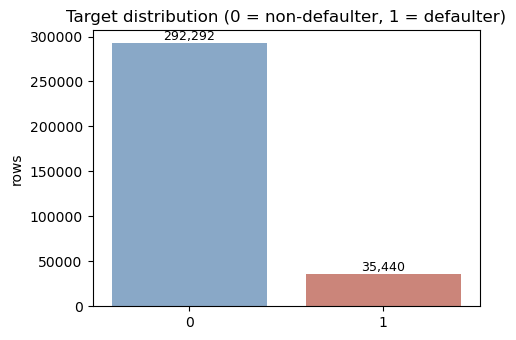

In [9]:
# quick sanity plot of the class balance
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df_clean, x=TARGET_COL, ax=ax, palette=["#7fa8d1", "#d97b6c"])
ax.set_title("Target distribution (0 = non-defaulter, 1 = defaulter)")
ax.set_xlabel(""); ax.set_ylabel("rows")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

## 6. Deduplicate, then split

Drops duplicates *after* PCA, which means it is comparing rows in a
rotated space rather than actual duplicate records. Dropping them on the cleaned features is
what he was reaching for.

In [10]:
# =====================================================================
# 6. DEDUPLICATE + STRATIFIED SPLIT
# =====================================================================
before = len(df_clean)
df_model = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(df_model):,} duplicate rows -> {len(df_model):,} remain")

X_all = df_model.drop(columns=[TARGET_COL])
y_all = df_model[TARGET_COL].astype(int)
FEATURE_NAMES = X_all.columns.tolist()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=RANDOM_STATE
)
print(f"train: {X_train_raw.shape}  |  test: {X_test_raw.shape}")
print(f"train positives: {y_train.sum():,} ({y_train.mean():.2%})")
print(f"test  positives: {y_test.sum():,} ({y_test.mean():.2%})")

save_art({"feature_names": FEATURE_NAMES,
          "train_index": X_train_raw.index.tolist(),
          "test_index":  X_test_raw.index.tolist()}, "02_split_meta.pkl")

Dropped 0 duplicate rows -> 327,732 remain
train: (262185, 136)  |  test: (65547, 136)
train positives: 28,352 (10.81%)
test  positives: 7,088 (10.81%)
   saved -> artifacts\02_split_meta.pkl  (1.5 MB)


{'feature_names': ['ACCT_AGE',
  'LIMIT',
  'OUTS',
  'ACCT_RESIDUAL_TENURE',
  'LOAN_TENURE',
  'INSTALAMT',
  'SI_FLG',
  'AGE',
  'VINTAGE',
  'KYC_SCR',
  'LOCKER_HLDR_IND',
  'UID_FLG',
  'KYC_FLG',
  'INB_FLG',
  'EKYC_FLG',
  'ONEMNTHCR',
  'ONEMNTHSDR',
  'ONEMNTHOUTSTANGBAL',
  'ONEMNTHAVGMTD',
  'ONEMNTHAVGQTD',
  'ONEMNTHAVGYTD',
  'TWOMNTHSCR',
  'TWOMNTHSDR',
  'TWOMNTHOUTSTANGBAL',
  'TWOMNTHAVGMTD',
  'TWOMNTHAVGQTD',
  'TWOMNTHAVGYTD',
  'THREEMNTHSCR',
  'THREEMNTHSDR',
  'THREEMNTHOUTSTANGBAL',
  'THREEMNTHAVGMTD',
  'THREEMNTHAVGQTD',
  'THREEMNTHAVGYTD',
  'FOURMNTHSCR',
  'FOURMNTHSDR',
  'FOURMNTHOUTSTANGBAL',
  'FOURMNTHAVGMTD',
  'FOURMNTHAVGQTD',
  'FOURMNTHAVGYTD',
  'FIVEMNTHSCR',
  'FIVEMNTHSDR',
  'FIVEMNTHOUTSTANGBAL',
  'FIVEMNTHAVGMTD',
  'FIVEMNTHAVGQTD',
  'FIVEMNTHAVGYTD',
  'SIXMNTHSCR',
  'SIXMNTHSDR',
  'SIXMNTHOUTSTANGBAL',
  'SIXMNTHAVGMTD',
  'SIXMNTHAVGQTD',
  'SIXMNTHAVGYTD',
  'SEVENMNTHSCR',
  'SEVENMNTHSDR',
  'SEVENMNTHOUTSTANGBAL',
  'SEV

## 7. Imputation safety net (MICE / MCMC)

Both of the imputers are defined here for completeness. The SBI cleaning already
leaves zero nulls, so in practice neither fires — the guard below only calls MICE if something
slipped through. Note that his MCMC routine is `O(iterations x missing_cells x n_cols)`; on a
frame this size it would not finish, so the guard uses MICE.

In [2]:
# =====================================================================
# 7. IMPUTATION
# =====================================================================
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from scipy.stats import norm


def mcmc_imputation(data, iterations=1000, burn_in=100):
    """ Gibbs-style sampler. Kept for reference — do not run on full data."""
    arr = data.values.astype(float)
    missing_idx = np.where(pd.isnull(arr))
    col_means = np.nanmean(arr, axis=0)
    for i, j in zip(*missing_idx):
        arr[i, j] = col_means[j] + np.random.randn()
    samples = {idx: [] for idx in zip(*missing_idx)}
    for it in range(iterations):
        for i, j in zip(*missing_idx):
            observed = arr[~np.isnan(arr[:, j]), j]
            val = (norm.rvs(loc=np.nanmean(observed), scale=np.nanstd(observed))
                   if observed.size else col_means[j] + np.random.randn())
            arr[i, j] = val
            if it >= burn_in:
                samples[(i, j)].append(val)
    for (i, j), vals in samples.items():
        arr[i, j] = np.mean(vals)
    return pd.DataFrame(arr, columns=data.columns, index=data.index)


def mice_imputation(data, max_iter=10, random_state=RANDOM_STATE):
    imputer = IterativeImputer(max_iter=max_iter, random_state=random_state)
    return pd.DataFrame(imputer.fit_transform(data),
                        columns=data.columns, index=data.index), imputer


n_null_train = int(X_train_raw.isnull().sum().sum())
n_null_test  = int(X_test_raw.isnull().sum().sum())
print(f"nulls in train: {n_null_train}   nulls in test: {n_null_test}")

if n_null_train == 0 and n_null_test == 0:
    print("Cleaning left nothing to impute — skipping MICE.")
    IMPUTER = None
else:
    print("Nulls found — running MICE on the training fold and applying to test.")
    def _fit_mice():
        imputed, imp = mice_imputation(X_train_raw)
        return {"frame": imputed, "imputer": imp}
    _mice = checkpoint("03_mice.pkl", _fit_mice)
    IMPUTER = _mice["imputer"]
    X_train_raw = _mice["frame"]
    X_test_raw = pd.DataFrame(IMPUTER.transform(X_test_raw),
                              columns=X_test_raw.columns, index=X_test_raw.index)

NameError: name 'X_train_raw' is not defined

## 8. Scale, then PCA

Fitted on the training fold only, then applied to test. `USE_PCA=False` skips the rotation and
keeps named features, which is what you want if you ever need SHAP on individual attributes.

In [12]:
# =====================================================================
# 8. STANDARDSCALER + PCA  (fitted on train only)
# =====================================================================
def _fit_transformers():
    sc = StandardScaler().fit(X_train_raw)
    Xtr = sc.transform(X_train_raw)
    out = {"scaler": sc, "pca": None, "n_components": Xtr.shape[1]}
    if USE_PCA:
        p = PCA(n_components=PCA_VARIANCE, random_state=RANDOM_STATE).fit(Xtr)
        out["pca"] = p
        out["n_components"] = p.n_components_
        print(f"   PCA: {Xtr.shape[1]} -> {p.n_components_} components, "
              f"{p.explained_variance_ratio_.sum():.3f} variance retained")
    return out

TRANS = checkpoint("04_transformers.pkl", _fit_transformers)
SCALER, PCA_MODEL = TRANS["scaler"], TRANS["pca"]

def to_model_space(X):
    """Cleaned dataframe -> the array the models actually see."""
    Z = SCALER.transform(X)
    return PCA_MODEL.transform(Z) if PCA_MODEL is not None else Z

X_train_p = to_model_space(X_train_raw)
X_test_p  = to_model_space(X_test_raw)

MODEL_FEATURE_NAMES = ([f"PC{i+1}" for i in range(X_train_p.shape[1])]
                       if PCA_MODEL is not None else FEATURE_NAMES)

print(f"model space -> train {X_train_p.shape}, test {X_test_p.shape}")
print(f"USE_PCA = {USE_PCA}")

[checkpoint] 04_transformers.pkl already exists — skipping compute
   loaded <- artifacts\04_transformers.pkl
model space -> train (262185, 136), test (65547, 136)
USE_PCA = False


In [13]:
# how much variance each component carries (only meaningful when USE_PCA=True)
if PCA_MODEL is not None:
    ev = PCA_MODEL.explained_variance_ratio_
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].bar(range(1, len(ev) + 1), ev, color="#7fa8d1")
    ax[0].set_title("Explained variance per component"); ax[0].set_xlabel("component")
    ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), color="#d97b6c")
    ax[1].axhline(PCA_VARIANCE, ls="--", c="gray")
    ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("component")
    plt.tight_layout(); plt.show()
else:
    print("USE_PCA is False — nothing to plot here.")

USE_PCA is False — nothing to plot here.


## 9. Resampling: undersample, then SMOTE

The two-stage scheme. `sampling_strategy` in imbalanced-learn is
**minority / majority after the operation**, so the undersample ratio has to be *larger* than
the current ratio or the call raises. The guard below checks that and tells you what a legal
value would be instead of failing halfway through a long run.

Only the training fold is resampled. The test fold keeps its natural ~10.8% prevalence, which
is the only way the metrics mean anything.

In [14]:
# =====================================================================
# 9. RANDOM UNDERSAMPLING -> SMOTE  (training fold only)
# =====================================================================
from collections import Counter

def _resample():
    if not HAS_IMBLEARN:
        print("   imbalanced-learn missing — returning the training fold untouched")
        return {"X": X_train_p, "y": y_train.values}

    print("   before:", Counter(y_train))
    cur_ratio = y_train.value_counts().min() / y_train.value_counts().max()
    print(f"   current minority/majority ratio: {cur_ratio:.4f}")

    Xr, yr = X_train_p, y_train.values
    if UNDERSAMPLE_RATIO <= cur_ratio:
        print(f"   [skip] UNDERSAMPLE_RATIO={UNDERSAMPLE_RATIO} is <= the current ratio "
              f"{cur_ratio:.4f}; undersampling cannot reduce the majority class to that. "
              f"Pick something above {cur_ratio:.3f} if you want this stage.")
    else:
        rus = RandomUnderSampler(sampling_strategy=UNDERSAMPLE_RATIO,
                                 random_state=RANDOM_STATE)
        Xr, yr = rus.fit_resample(Xr, yr)
        print("   after undersampling:", Counter(yr))

    post = pd.Series(yr).value_counts()
    post_ratio = post.min() / post.max()
    if SMOTE_RATIO <= post_ratio:
        print(f"   [skip] SMOTE_RATIO={SMOTE_RATIO} is <= the post-undersample ratio "
              f"{post_ratio:.4f}; SMOTE only oversamples upward.")
    else:
        sm = SMOTE(sampling_strategy=SMOTE_RATIO, random_state=RANDOM_STATE)
        Xr, yr = sm.fit_resample(Xr, yr)
        print("   after SMOTE:", Counter(yr))

    return {"X": Xr, "y": yr}

_res = checkpoint("05_resampled.pkl", _resample)
X_res, y_res = _res["X"], _res["y"]
print(f"\nresampled training set: {X_res.shape}, positive rate {np.mean(y_res):.2%}")

# smaller views for the models that cannot take 200k rows
def subsample(X, y, cap, seed=RANDOM_STATE):
    if len(y) <= cap:
        return X, y
    idx = np.random.RandomState(seed).choice(len(y), cap, replace=False)
    return X[idx], np.asarray(y)[idx]

X_heavy, y_heavy = subsample(X_res, y_res, HEAVY_MODEL_CAP)
X_tune,  y_tune  = subsample(X_res, y_res, TUNING_CAP)
print(f"heavy-model view: {X_heavy.shape}   tuning view: {X_tune.shape}")

[checkpoint] 05_resampled.pkl already exists — skipping compute
   loaded <- artifacts\05_resampled.pkl

resampled training set: (262185, 136), positive rate 10.81%
heavy-model view: (15000, 136)   tuning view: (80000, 136)


## 10. Scoring helpers

One evaluation function for every model so the leaderboard at the end is apples to apples.
All scores are on the **untouched test fold**, never on resampled data — the notebook
reports metrics on the SMOTE'd training set in a couple of places, which flatters every model
by a wide margin.

KS is included alongside AUC because it is the statistic a credit risk team will actually ask for.

In [15]:
# =====================================================================
# 10. EVALUATION HELPERS
# =====================================================================
RESULTS = []

def ks_statistic(y_true, proba):
    fpr, tpr, _ = roc_curve(y_true, proba)
    return float(np.max(tpr - fpr))

def evaluate(name, y_true, proba, threshold=0.5, note="", record=True, quiet=False):
    proba = np.asarray(proba).ravel()
    pred = (proba >= threshold).astype(int)
    row = {
        "model":     name,
        "roc_auc":   roc_auc_score(y_true, proba),
        "pr_auc":    average_precision_score(y_true, proba),
        "ks":        ks_statistic(y_true, proba),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall":    recall_score(y_true, pred, zero_division=0),
        "f1":        f1_score(y_true, pred, zero_division=0),
        "brier":     brier_score_loss(y_true, proba),
        "threshold": float(threshold),
        "note":      note,
    }
    if record:
        RESULTS.append(row)
    if not quiet:
        print(f"  {name:<34} AUC {row['roc_auc']:.4f} | PR-AUC {row['pr_auc']:.4f} | "
              f"KS {row['ks']:.4f} | P {row['precision']:.3f} | R {row['recall']:.3f} | "
              f"F1 {row['f1']:.3f}")
    return row

def leaderboard():
    if not RESULTS:
        print("nothing scored yet"); return None
    lb = (pd.DataFrame(RESULTS)
            .sort_values("roc_auc", ascending=False)
            .reset_index(drop=True))
    return lb

def threshold_for_recall(y_true, proba, target_recall=0.85):
    """Lowest threshold that still reaches the target recall."""
    prec, rec, thr = precision_recall_curve(y_true, proba)
    ix = int(np.argmin(np.abs(rec[:-1] - target_recall)))
    return float(thr[ix])

def youden_threshold(y_true, proba):
    fpr, tpr, thr = roc_curve(y_true, proba)
    return float(thr[int(np.argmax(tpr - fpr))])

def plot_confusion(y_true, proba, threshold, title):
    cm = confusion_matrix(y_true, (np.asarray(proba).ravel() >= threshold).astype(int))
    tn, fp, fn, tp = cm.ravel()
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
    ax.set_title(f"{title}\nthr={threshold:.3f}  |  caught {tp:,} of {tp+fn:,} defaulters")
    plt.tight_layout(); plt.show()
    return dict(tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

print("evaluation helpers ready")

evaluation helpers ready


## 11. Baseline models

XGBoost and Random Forest on their own, exactly as the notebook does before it starts
ensembling. These are the numbers every later ensemble has to beat — and on your project the
honest finding last time was that a well-tuned single booster was already at the ceiling. Keep
that possibility live; if the ensembles land within noise of these two, that is a result, not a
failure.

In [16]:
# =====================================================================
# 11. BASELINE MODELS
# =====================================================================
def _fit_xgb():
    m = XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss",
                      n_jobs=-1, tree_method="hist")
    m.fit(X_res, y_res)
    return m

def _fit_rf():
    m = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                               n_estimators=RF_N_ESTIMATORS,
                               max_depth=RF_MAX_DEPTH,
                               min_samples_leaf=RF_MIN_LEAF)
    m.fit(X_res, y_res)
    return m

if HAS_XGB:
    xgb_base = checkpoint("10_xgb_base.pkl", _fit_xgb)
    evaluate("XGBoost (baseline)", y_test, xgb_base.predict_proba(X_test_p)[:, 1])

rf_base = checkpoint("11_rf_base.pkl", _fit_rf)
evaluate("RandomForest (baseline)", y_test, rf_base.predict_proba(X_test_p)[:, 1])

[checkpoint] 10_xgb_base.pkl already exists — skipping compute
   loaded <- artifacts\10_xgb_base.pkl
  XGBoost (baseline)                 AUC 0.9208 | PR-AUC 0.6435 | KS 0.6902 | P 0.695 | R 0.438 | F1 0.537
[checkpoint] 11_rf_base.pkl already exists — skipping compute
   loaded <- artifacts\11_rf_base.pkl
  RandomForest (baseline)            AUC 0.8751 | PR-AUC 0.5177 | KS 0.5942 | P 0.741 | R 0.161 | F1 0.265


{'model': 'RandomForest (baseline)',
 'roc_auc': 0.875099187321847,
 'pr_auc': 0.5177139157863296,
 'ks': 0.5941500085510723,
 'precision': 0.7414128321451717,
 'recall': 0.1613995485327314,
 'f1': 0.26509095122233806,
 'brier': 0.07114634987642807,
 'threshold': 0.5,
 'note': ''}

               precision    recall  f1-score   support

Non-Defaulter       0.93      0.98      0.96     58459
    Defaulter       0.70      0.44      0.54      7088

     accuracy                           0.92     65547
    macro avg       0.82      0.71      0.75     65547
 weighted avg       0.91      0.92      0.91     65547



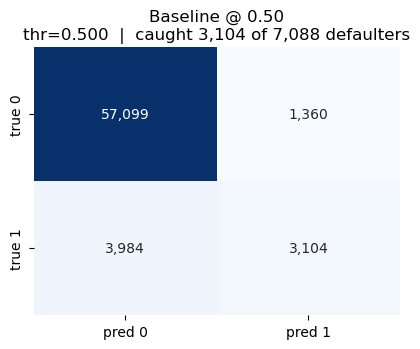

In [17]:
# full classification report for the stronger baseline
_base = xgb_base if HAS_XGB else rf_base
_p = _base.predict_proba(X_test_p)[:, 1]
print(classification_report(y_test, (_p >= 0.5).astype(int),
                            target_names=["Non-Defaulter", "Defaulter"]))
_ = plot_confusion(y_test, _p, 0.5, "Baseline @ 0.50")

## 12. Model zoo

The seven-model comparison — XGBoost, Random Forest, LightGBM, Naive Bayes, Logistic
Regression, SVC, CatBoost — each fitted, checkpointed, and scored on the same test fold.

SVC and KNN are fitted on `HEAVY_MODEL_CAP` rows because both scale badly. Turn them off in the
config if you want a faster pass.

In [18]:
# =====================================================================
# 12. MODEL ZOO
# =====================================================================
ZOO_SPECS = {
    "LogisticRegression": (lambda: LogisticRegression(random_state=RANDOM_STATE,
                                                      max_iter=1000, n_jobs=-1), False),
    "GaussianNB":         (lambda: GaussianNB(), False),
    "RandomForest":       (lambda: RandomForestClassifier(random_state=RANDOM_STATE,
                                                          n_estimators=RF_N_ESTIMATORS,
                                                          max_depth=RF_MAX_DEPTH,
                                                          min_samples_leaf=RF_MIN_LEAF,
                                                          n_jobs=-1), False),
}
if HAS_XGB:
    ZOO_SPECS["XGBoost"]  = (lambda: XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                                   eval_metric="logloss", tree_method="hist"), False)
if HAS_LGB:
    ZOO_SPECS["LightGBM"] = (lambda: LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                                    verbose=-1), False)
if HAS_CAT:
    ZOO_SPECS["CatBoost"] = (lambda: CatBoostClassifier(random_state=RANDOM_STATE,
                                                        verbose=0), False)
if RUN_SVC:
    ZOO_SPECS["SVC"]      = (lambda: SVC(probability=True, random_state=RANDOM_STATE), True)
if RUN_KNN:
    ZOO_SPECS["KNN"]      = (lambda: KNeighborsClassifier(n_jobs=-1), True)

ZOO = {}
for name, (factory, heavy) in ZOO_SPECS.items():
    Xf, yf = (X_heavy, y_heavy) if heavy else (X_res, y_res)
    def _fit(factory=factory, Xf=Xf, yf=yf):
        m = factory(); m.fit(Xf, yf); return m
    ZOO[name] = checkpoint(f"12_zoo_{name}.pkl", _fit)
    tag = f"{name}" + (f" (on {len(yf):,} rows)" if heavy else "")
    evaluate(tag, y_test, ZOO[name].predict_proba(X_test_p)[:, 1], note="zoo")

print(f"\n{len(ZOO)} models trained and cached")

[checkpoint] 12_zoo_LogisticRegression.pkl already exists — skipping compute
   loaded <- artifacts\12_zoo_LogisticRegression.pkl
  LogisticRegression                 AUC 0.8261 | PR-AUC 0.4039 | KS 0.5102 | P 0.617 | R 0.135 | F1 0.222
[checkpoint] 12_zoo_GaussianNB.pkl already exists — skipping compute
   loaded <- artifacts\12_zoo_GaussianNB.pkl
  GaussianNB                         AUC 0.7317 | PR-AUC 0.2229 | KS 0.3745 | P 0.211 | R 0.684 | F1 0.323
[checkpoint] 12_zoo_RandomForest.pkl already exists — skipping compute
   loaded <- artifacts\12_zoo_RandomForest.pkl
  RandomForest                       AUC 0.8751 | PR-AUC 0.5177 | KS 0.5942 | P 0.741 | R 0.161 | F1 0.265
[checkpoint] 12_zoo_XGBoost.pkl already exists — skipping compute
   loaded <- artifacts\12_zoo_XGBoost.pkl
  XGBoost                            AUC 0.9208 | PR-AUC 0.6435 | KS 0.6902 | P 0.695 | R 0.438 | F1 0.537
[checkpoint] 12_zoo_LightGBM.pkl already exists — skipping compute
   loaded <- artifacts\12_zoo_Light

In [3]:
# ---- majority vote across the whole zoo ( "LogitShift" cell) ----
zoo_probas = np.column_stack([m.predict_proba(X_test_p)[:, 1] for m in ZOO.values()])
zoo_hard   = (zoo_probas >= 0.5).astype(int)
majority   = (zoo_hard.mean(axis=1) >= 0.5).astype(int)
mean_proba = zoo_probas.mean(axis=1)

evaluate("Zoo mean-probability blend", y_test, mean_proba, note="zoo blend")
print("\nMajority-vote classification report:")
print(classification_report(y_test, majority,
                            target_names=["Non-Defaulter", "Defaulter"]))

NameError: name 'np' is not defined

## 13. Hyperparameter search: RandomizedSearchCV

The `GridSearchCV` for Random Forest and XGBoost. His grids are 81 and 16 fits before
the 5-fold multiplier, on data this size that is a very long afternoon — so this is
`RandomizedSearchCV` over the same ranges with `N_RANDOM_SEARCH` draws and 3-fold, scored on
ROC AUC rather than accuracy. Accuracy on an imbalanced target is close to meaningless; a model
that predicts all zeros scores 89%.

In [20]:
# =====================================================================
# 13. RANDOMIZED SEARCH (senior's GridSearchCV, made affordable)
# =====================================================================
# Senior's grid had max_depth=None and min_samples_leaf=1, which on this row count
# builds trees with ~200k leaves each. Bounded here for the same reason as above.
RF_SPACE = {
    "n_estimators":     [100, 200, 300],
    "max_depth":        [10, 16, 22],
    "min_samples_split":[2, 10, 20],
    "min_samples_leaf": [5, 20, 50],
}
XGB_SPACE = {
    "n_estimators":  [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth":     [3, 6, 9],
    "subsample":     [0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

def _search(estimator, space, tag):
    rs = RandomizedSearchCV(estimator, space, n_iter=N_RANDOM_SEARCH, cv=3,
                            scoring="roc_auc", n_jobs=-1,
                            random_state=RANDOM_STATE, verbose=0)
    rs.fit(X_tune, y_tune)
    print(f"   {tag} best CV AUC {rs.best_score_:.4f} | {rs.best_params_}")
    return {"best_params": rs.best_params_, "best_score": rs.best_score_}

rf_search = checkpoint("13_rf_search.pkl", _search,
                       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                       RF_SPACE, "RandomForest")

def _fit_best_rf():
    m = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                               **rf_search["best_params"])
    m.fit(X_res, y_res); return m

best_rf = checkpoint("13_rf_best.pkl", _fit_best_rf)
evaluate("RandomForest (tuned)", y_test, best_rf.predict_proba(X_test_p)[:, 1], note="tuned")

if HAS_XGB:
    xgb_search = checkpoint("13_xgb_search.pkl", _search,
                            XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                          eval_metric="logloss", tree_method="hist"),
                            XGB_SPACE, "XGBoost")
    def _fit_best_xgb():
        m = XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss",
                          tree_method="hist", **xgb_search["best_params"])
        m.fit(X_res, y_res); return m
    best_xgb = checkpoint("13_xgb_best.pkl", _fit_best_xgb)
    evaluate("XGBoost (tuned)", y_test, best_xgb.predict_proba(X_test_p)[:, 1], note="tuned")
else:
    best_xgb = None

[checkpoint] 13_rf_search.pkl already exists — skipping compute
   loaded <- artifacts\13_rf_search.pkl
[checkpoint] 13_rf_best.pkl already exists — skipping compute
   loaded <- artifacts\13_rf_best.pkl
  RandomForest (tuned)               AUC 0.8748 | PR-AUC 0.5197 | KS 0.5936 | P 0.726 | R 0.167 | F1 0.272
[checkpoint] 13_xgb_search.pkl already exists — skipping compute
   loaded <- artifacts\13_xgb_search.pkl
[checkpoint] 13_xgb_best.pkl already exists — skipping compute
   loaded <- artifacts\13_xgb_best.pkl
  XGBoost (tuned)                    AUC 0.9222 | PR-AUC 0.6454 | KS 0.6918 | P 0.719 | R 0.402 | F1 0.516


## 14. Soft-voting ensemble

`VotingClassifier` over the tuned RF, tuned XGB, logistic regression, SVC and KNN — the
five-model soft vote. SVC and KNN drag the fit time up badly here, so the whole ensemble is
fitted on the heavy-model view.

In [21]:
# =====================================================================
# 14. SOFT VOTING ENSEMBLE
# =====================================================================
def _fit_voting():
    est = [("rf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                         **rf_search["best_params"])),
           ("lr", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))]
    if HAS_XGB:
        est.append(("xgb", XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                         eval_metric="logloss", tree_method="hist",
                                         **xgb_search["best_params"])))
    if RUN_SVC:
        est.append(("svc", SVC(probability=True, random_state=RANDOM_STATE)))
    if RUN_KNN:
        est.append(("knn", KNeighborsClassifier(n_jobs=-1)))

    heavy = RUN_SVC or RUN_KNN
    Xf, yf = (X_heavy, y_heavy) if heavy else (X_res, y_res)
    print(f"   fitting {len(est)} estimators on {len(yf):,} rows")
    vc = VotingClassifier(estimators=est, voting="soft", n_jobs=-1)
    vc.fit(Xf, yf)
    return vc

voting = checkpoint("14_voting.pkl", _fit_voting)
vote_proba = voting.predict_proba(X_test_p)[:, 1]
evaluate("Soft VotingClassifier", y_test, vote_proba, note="ensemble")
print()
print(classification_report(y_test, (vote_proba >= 0.5).astype(int),
                            target_names=["Non-Defaulter", "Defaulter"]))

[checkpoint] 14_voting.pkl already exists — skipping compute
   loaded <- artifacts\14_voting.pkl
  Soft VotingClassifier              AUC 0.8540 | PR-AUC 0.4765 | KS 0.5510 | P 0.716 | R 0.127 | F1 0.216

               precision    recall  f1-score   support

Non-Defaulter       0.90      0.99      0.95     58459
    Defaulter       0.72      0.13      0.22      7088

     accuracy                           0.90     65547
    macro avg       0.81      0.56      0.58     65547
 weighted avg       0.88      0.90      0.87     65547



## 15. Optuna tuning for XGBoost, LightGBM and CatBoost

The three objective functions. Two changes:

- **Scored on an inner validation split carved out of the training data, not on `X_test`.**
  His version optimises against the test fold directly, so the reported test score is no longer
  an estimate of anything.
- **Optimises ROC AUC instead of weighted F1 at a fixed 0.5 cut.** You want a good ranking; the
  threshold is a separate decision made later against the business cost of a miss.

Each study is checkpointed as a list of trial parameter sets, so the ensemble below can be
rebuilt without re-running the search.

In [22]:
# =====================================================================
# 15. OPTUNA
# =====================================================================
X_fit, X_inner, y_fit, y_inner = train_test_split(
    X_tune, y_tune, test_size=0.25, stratify=y_tune, random_state=RANDOM_STATE)
print(f"inner tuning split: fit {X_fit.shape}, validate {X_inner.shape}")

def _score(model):
    model.fit(X_fit, y_fit)
    return roc_auc_score(y_inner, model.predict_proba(X_inner)[:, 1])

def obj_xgb(trial):
    p = dict(max_depth=trial.suggest_int("max_depth", 3, 10),
             learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
             n_estimators=trial.suggest_int("n_estimators", 100, 400),
             gamma=trial.suggest_float("gamma", 0.0, 5.0),
             min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
             subsample=trial.suggest_float("subsample", 0.5, 1.0),
             colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0))
    return _score(XGBClassifier(**p, random_state=RANDOM_STATE, n_jobs=-1,
                                eval_metric="logloss", tree_method="hist"))

def obj_lgb(trial):
    p = dict(num_leaves=trial.suggest_int("num_leaves", 20, 150),
             learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
             n_estimators=trial.suggest_int("n_estimators", 100, 400),
             min_child_samples=trial.suggest_int("min_child_samples", 20, 100),
             subsample=trial.suggest_float("subsample", 0.6, 1.0),
             colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0))
    return _score(LGBMClassifier(**p, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1))

def obj_cat(trial):
    p = dict(depth=trial.suggest_int("depth", 3, 10),
             learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
             n_estimators=trial.suggest_int("n_estimators", 100, 400),
             l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0))
    return _score(CatBoostClassifier(**p, random_state=RANDOM_STATE, verbose=0))

def run_study(objective, tag, n_trials=None):
    st = optuna.create_study(direction="maximize",
                             sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    st.optimize(objective, n_trials=n_trials or N_OPTUNA_TRIALS, show_progress_bar=False)
    top = sorted([t for t in st.trials if t.value is not None],
                 key=lambda t: t.value, reverse=True)[:TOP_TRIALS_PER_MODEL]
    print(f"   {tag}: best inner AUC {st.best_value:.4f}")
    return {"best_params": st.best_params, "best_value": st.best_value,
            "top_params": [t.params for t in top]}

STUDIES = {}
if HAS_OPTUNA and HAS_XGB:
    STUDIES["xgb"] = checkpoint("15_study_xgb.pkl", run_study, obj_xgb, "XGBoost")
if HAS_OPTUNA and HAS_LGB:
    STUDIES["lgb"] = checkpoint("15_study_lgb.pkl", run_study, obj_lgb, "LightGBM")
if HAS_OPTUNA and HAS_CAT:
    STUDIES["cat"] = checkpoint("15_study_cat.pkl", run_study, obj_cat, "CatBoost")

if not STUDIES:
    print("optuna or all boosters missing — skipping this stage")

inner tuning split: fit (60000, 136), validate (20000, 136)
[checkpoint] 15_study_xgb.pkl already exists — skipping compute
   loaded <- artifacts\15_study_xgb.pkl
[checkpoint] 15_study_lgb.pkl already exists — skipping compute
   loaded <- artifacts\15_study_lgb.pkl
[checkpoint] 15_study_cat.pkl already exists — skipping compute
   loaded <- artifacts\15_study_cat.pkl


In [23]:
# refit each family's single best configuration on the full resampled training set
BEST_MODELS = {}

def _mk(kind, params):
    if kind == "xgb":
        return XGBClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1,
                             eval_metric="logloss", tree_method="hist")
    if kind == "lgb":
        return LGBMClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    return CatBoostClassifier(**params, random_state=RANDOM_STATE, verbose=0)

for kind, study in STUDIES.items():
    def _fit(kind=kind, study=study):
        m = _mk(kind, study["best_params"]); m.fit(X_res, y_res); return m
    BEST_MODELS[kind] = checkpoint(f"15_best_{kind}.pkl", _fit)
    evaluate(f"{kind.upper()} (Optuna best)", y_test,
             BEST_MODELS[kind].predict_proba(X_test_p)[:, 1], note="optuna")

[checkpoint] 15_best_xgb.pkl already exists — skipping compute
   loaded <- artifacts\15_best_xgb.pkl
  XGB (Optuna best)                  AUC 0.9270 | PR-AUC 0.6644 | KS 0.7010 | P 0.727 | R 0.428 | F1 0.539
[checkpoint] 15_best_lgb.pkl already exists — skipping compute
   loaded <- artifacts\15_best_lgb.pkl
  LGB (Optuna best)                  AUC 0.9291 | PR-AUC 0.6757 | KS 0.7044 | P 0.732 | R 0.443 | F1 0.552
[checkpoint] 15_best_cat.pkl already exists — skipping compute
   loaded <- artifacts\15_best_cat.pkl
  CAT (Optuna best)                  AUC 0.9220 | PR-AUC 0.6528 | KS 0.6893 | P 0.733 | R 0.416 | F1 0.530


## 16. Top-trials voting ensemble

The final construction: take the best few trials from each family, fit them all, and
soft-vote. Cross-validated on the training fold with `ENSEMBLE_CV_FOLDS` (his 100 folds would be
a hundred fits of a fifteen-model ensemble), then scored on the held-out test fold with a
threshold picked by Youden's J.

[checkpoint] computing 16_top_ensemble.pkl ...
   9 tuned estimators in the ensemble
[checkpoint] 16_top_ensemble.pkl finished in 882.4s
   saved -> artifacts\16_top_ensemble.pkl  (36.5 MB)
  Top-trials VotingClassifier        AUC 0.9278 | PR-AUC 0.6689 | KS 0.7033 | P 0.407 | R 0.854 | F1 0.551

Youden J threshold: 0.1199
               precision    recall  f1-score   support

Non-Defaulter       0.98      0.85      0.91     58459
    Defaulter       0.41      0.85      0.55      7088

     accuracy                           0.85     65547
    macro avg       0.69      0.85      0.73     65547
 weighted avg       0.92      0.85      0.87     65547



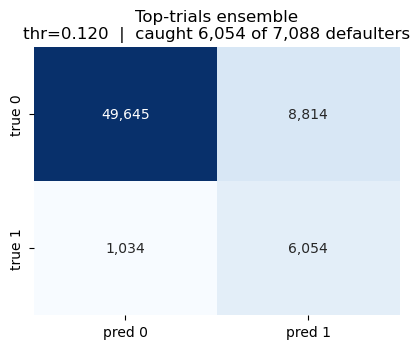

In [24]:
# =====================================================================
# 16. TOP-TRIALS SOFT VOTE
# =====================================================================
def _fit_top_ensemble():
    est = []
    for kind, study in STUDIES.items():
        for i, params in enumerate(study["top_params"]):
            est.append((f"{kind}_{i}", _mk(kind, params)))
    if not est:
        return None
    print(f"   {len(est)} tuned estimators in the ensemble")
    vc = VotingClassifier(estimators=est, voting="soft", n_jobs=-1)
    vc.fit(X_res, y_res)
    return vc

top_ensemble = checkpoint("16_top_ensemble.pkl", _fit_top_ensemble)

if top_ensemble is not None:
    te_proba = top_ensemble.predict_proba(X_test_p)[:, 1]
    thr_j = youden_threshold(y_test, te_proba)
    evaluate("Top-trials VotingClassifier", y_test, te_proba, threshold=thr_j,
             note="ensemble @ Youden J")
    print(f"\nYouden J threshold: {thr_j:.4f}")
    print(classification_report(y_test, (te_proba >= thr_j).astype(int),
                                target_names=["Non-Defaulter", "Defaulter"]))
    _ = plot_confusion(y_test, te_proba, thr_j, "Top-trials ensemble")

In [25]:
# out-of-fold CV on the training fold, to see whether the ensemble is stable
def _ensemble_cv():
    if top_ensemble is None:
        return None
    Xc, yc = subsample(X_res, y_res, min(len(y_res), 60_000))
    skf = StratifiedKFold(n_splits=ENSEMBLE_CV_FOLDS, shuffle=True,
                          random_state=RANDOM_STATE)
    oof = cross_val_predict(top_ensemble, Xc, yc, cv=skf,
                            method="predict_proba", n_jobs=1)[:, 1]
    return {"oof": oof, "y": yc, "auc": roc_auc_score(yc, oof)}

cv_res = checkpoint("16_ensemble_cv.pkl", _ensemble_cv)
if cv_res:
    print(f"{ENSEMBLE_CV_FOLDS}-fold OOF AUC on resampled training data: {cv_res['auc']:.4f}")
    print("(higher than the test AUC is expected — SMOTE'd data is easier to separate)")

[checkpoint] computing 16_ensemble_cv.pkl ...
[checkpoint] 16_ensemble_cv.pkl finished in 1,730.6s
   saved -> artifacts\16_ensemble_cv.pkl  (0.7 MB)
5-fold OOF AUC on resampled training data: 0.9114
(higher than the test AUC is expected — SMOTE'd data is easier to separate)


## 17. Stacking

`StackingClassifier` with a logistic-regression meta-learner over the tuned base models. This is
the same construction your original SBI notebook used with the NN and LightGBM, so it is the
direct comparison point: if the stack lands on top of the best single booster again, that is
worth stating plainly rather than burying.

In [27]:
# =====================================================================
# 17. STACKING
# =====================================================================
def _fit_stack():
    est = [("rf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                         **rf_search["best_params"])),
           ("lr", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))]
    for kind, study in STUDIES.items():
        est.append((kind, _mk(kind, study["best_params"])))
    print(f"   stacking {len(est)} base learners")
    sc = StackingClassifier(
        estimators=est,
        final_estimator=LogisticRegression(class_weight="balanced", max_iter=1000),
        cv=3, n_jobs=-1, passthrough=False)
    sc.fit(X_res, y_res)
    return sc

stack = checkpoint("17_stacking.pkl", _fit_stack)
stack_proba = stack.predict_proba(X_test_p)[:, 1]
evaluate("StackingClassifier (LR meta)", y_test, stack_proba, note="ensemble")
print()
print(classification_report(y_test, (stack_proba >= 0.5).astype(int),
                            target_names=["Non-Defaulter", "Defaulter"]))

print("\nMeta-learner coefficients (one per base model, order as listed above):")
print(np.round(stack.final_estimator_.coef_.ravel(), 4))

[checkpoint] computing 17_stacking.pkl ...
   stacking 5 base learners
[checkpoint] 17_stacking.pkl finished in 1,768.5s
   saved -> artifacts\17_stacking.pkl  (162.4 MB)
  StackingClassifier (LR meta)       AUC 0.9291 | PR-AUC 0.6735 | KS 0.7050 | P 0.491 | R 0.777 | F1 0.602

               precision    recall  f1-score   support

Non-Defaulter       0.97      0.90      0.94     58459
    Defaulter       0.49      0.78      0.60      7088

     accuracy                           0.89     65547
    macro avg       0.73      0.84      0.77     65547
 weighted avg       0.92      0.89      0.90     65547


Meta-learner coefficients (one per base model, order as listed above):
[-0.1871 -0.2896  3.0624  4.2683  2.7553]


## 18. Recursive feature elimination

The selects 5 features with RFE and a Random Forest estimator. Five is very aggressive
for 138 inputs — `N_RFE_FEATURES` below is set to 30, and RFE is run on a subsample with a light
forest because the full version refits the model once per elimination step.

If `USE_PCA=True` this ranks principal components, which tells you little. It is worth running
with `USE_PCA=False` where the output is actual attribute names.

In [28]:
# =====================================================================
# 18. RFE
# =====================================================================
N_RFE_FEATURES = 30

def _run_rfe():
    Xs, ys = subsample(X_res, y_res, min(len(y_res), 30_000))
    est = RandomForestClassifier(n_estimators=60, max_depth=12,
                                 random_state=RANDOM_STATE, n_jobs=-1)
    sel = RFE(est, n_features_to_select=min(N_RFE_FEATURES, Xs.shape[1]), step=0.15)
    sel.fit(Xs, ys)
    return {"support": sel.support_, "ranking": sel.ranking_}

rfe_res = checkpoint("18_rfe.pkl", _run_rfe)
sel_names = [n for n, keep in zip(MODEL_FEATURE_NAMES, rfe_res["support"]) if keep]
print(f"RFE kept {len(sel_names)} of {len(MODEL_FEATURE_NAMES)}:")
for n in sel_names:
    print("  -", n)

# does a model on just those features hold up?
if HAS_LGB:
    mask = rfe_res["support"]
    def _fit_rfe_model():
        m = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
        m.fit(X_res[:, mask], y_res); return m
    rfe_model = checkpoint("18_rfe_model.pkl", _fit_rfe_model)
    evaluate(f"LightGBM on {len(sel_names)} RFE features", y_test,
             rfe_model.predict_proba(X_test_p[:, mask])[:, 1], note="feature selection")

[checkpoint] computing 18_rfe.pkl ...
[checkpoint] 18_rfe.pkl finished in 21.6s
   saved -> artifacts\18_rfe.pkl  (0.0 MB)
RFE kept 30 of 136:
  - ACCT_AGE
  - OUTS
  - ACCT_RESIDUAL_TENURE
  - LOAN_TENURE
  - AGE
  - VINTAGE
  - ONEMNTHCR
  - ONEMNTHOUTSTANGBAL
  - ONEMNTHAVGMTD
  - TWOMNTHSCR
  - FIVEMNTHAVGMTD
  - ALL_LON_LIMIT
  - ALL_LON_OUTS
  - OLDEST_LON_TAKEN
  - LATEST_LON_TAKEN
  - LATEST_RESIDUAL_TENURE
  - OLDEST_RESIDUAL_TENURE
  - TOT_IRAC_CHNG
  - TIMES_IRAC_SLIP
  - LAST_1_YR_RG2
  - CRIFF_11
  - CRIFF_22
  - CRIFF_33
  - CRIFF_55
  - CRIFF_66
  - PRI_CURRENT_BALANCE1
  - PRIMARY_INSTAL_AMT1
  - CREDIT_HISTORY_LENGTH1
  - LATEST_CR_DAYS
  - UNIQUE_ID
[checkpoint] computing 18_rfe_model.pkl ...
[checkpoint] 18_rfe_model.pkl finished in 3.4s
   saved -> artifacts\18_rfe_model.pkl  (0.4 MB)
  LightGBM on 30 RFE features        AUC 0.9078 | PR-AUC 0.5895 | KS 0.6600 | P 0.677 | R 0.356 | F1 0.467


## 19. Genetic feature selection (DEAP)

Off by default — this is the slowest cell in the notebook. Two fixes to the version:
his fitness function scores the model on its own **training** data, so it rewards memorisation
and will happily keep every feature; and `X_train[:, selected]` fails on a DataFrame. Fitness
here is validation AUC on a held-out slice, with a small penalty per feature so the search
actually prefers compact solutions.

In [29]:
# =====================================================================
# 19. GENETIC ALGORITHM FEATURE SELECTION
# =====================================================================
GA_POP, GA_GENS, GA_CX, GA_MUT = 20, 8, 0.8, 0.2
GA_SIZE_PENALTY = 0.0005

if not RUN_GA:
    print("RUN_GA is False — skipping. Set it to True in the config to run this.")
else:
    from deap import base, creator, tools, algorithms

    Xga, yga = subsample(X_res, y_res, min(len(y_res), 20_000), seed=7)
    Xg_fit, Xg_val, yg_fit, yg_val = train_test_split(
        Xga, yga, test_size=0.3, stratify=yga, random_state=RANDOM_STATE)
    n_feat = Xga.shape[1]

    def fitness(ind):
        idx = [i for i, b in enumerate(ind) if b]
        if not idx:
            return (0.0,)
        est = (LGBMClassifier(n_estimators=80, random_state=RANDOM_STATE,
                              n_jobs=-1, verbose=-1) if HAS_LGB
               else RandomForestClassifier(n_estimators=60, max_depth=10,
                                           random_state=RANDOM_STATE, n_jobs=-1))
        est.fit(Xg_fit[:, idx], yg_fit)
        auc = roc_auc_score(yg_val, est.predict_proba(Xg_val[:, idx])[:, 1])
        return (auc - GA_SIZE_PENALTY * len(idx),)

    def _run_ga():
        if hasattr(creator, "FitnessMax"): del creator.FitnessMax
        if hasattr(creator, "Individual"): del creator.Individual
        creator.create("FitnessMax", base.Fitness, weights=(1.0,))
        creator.create("Individual", list, fitness=creator.FitnessMax)
        tb = base.Toolbox()
        tb.register("attr_bool", lambda: int(np.random.rand() < 0.5))
        tb.register("individual", tools.initRepeat, creator.Individual,
                    tb.attr_bool, n_feat)
        tb.register("population", tools.initRepeat, list, tb.individual)
        tb.register("mate", tools.cxUniform, indpb=0.5)
        tb.register("mutate", tools.mutFlipBit, indpb=0.1)
        tb.register("select", tools.selTournament, tournsize=3)
        tb.register("evaluate", fitness)
        pop = tb.population(n=GA_POP)
        pop, _ = algorithms.eaSimple(pop, tb, cxpb=GA_CX, mutpb=GA_MUT,
                                     ngen=GA_GENS, verbose=True)
        best = tools.selBest(pop, k=1)[0]
        return {"mask": np.array(best, dtype=bool), "fitness": float(best.fitness.values[0])}

    ga_res = checkpoint("19_ga.pkl", _run_ga)
    ga_names = [n for n, k in zip(MODEL_FEATURE_NAMES, ga_res["mask"]) if k]
    print(f"\nGA selected {len(ga_names)} features, fitness {ga_res['fitness']:.4f}")
    print(ga_names[:40])

    def _fit_ga_model():
        est = (LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
               if HAS_LGB else RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
        est.fit(X_res[:, ga_res["mask"]], y_res); return est

    ga_model = checkpoint("19_ga_model.pkl", _fit_ga_model)
    evaluate(f"GA-selected ({len(ga_names)} features)", y_test,
             ga_model.predict_proba(X_test_p[:, ga_res["mask"]])[:, 1],
             note="feature selection")

RUN_GA is False — skipping. Set it to True in the config to run this.


## 20. Optional: your Keras net

Not part of the pipeline — kept so the neural network you built for the hackathon
still has a place in the comparison. Off by default; set `RUN_NN = True` and install
`scikeras[tensorflow]` to include it.

In [30]:
# =====================================================================
# 20. NEURAL NETWORK (optional)
# =====================================================================
if not RUN_NN:
    print("RUN_NN is False — skipping.")
else:
    import tensorflow as tf
    from tensorflow.keras import layers, models
    from sklearn.utils.class_weight import compute_class_weight

    cw = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
    class_weight_dict = dict(enumerate(cw))
    print("class weights:", class_weight_dict)

    def build_nn_model(input_dim):
        m = models.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(128, activation="relu"),
            layers.Dropout(0.3),
            layers.Dense(64, activation="relu"),
            layers.Dropout(0.2),
            layers.Dense(32, activation="relu"),
            layers.Dense(1, activation="sigmoid"),
        ])
        m.compile(optimizer="adam", loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
        return m

    nn_path = art("20_nn.keras")
    if os.path.exists(nn_path) and not FORCE_RERUN:
        nn = tf.keras.models.load_model(nn_path)
        print("   loaded cached network")
    else:
        nn = build_nn_model(X_train_p.shape[1])
        nn.fit(X_train_p, y_train.values, epochs=50, batch_size=512,
               validation_data=(X_test_p, y_test.values),
               class_weight=class_weight_dict, verbose=2)
        nn.save(nn_path); print(f"   saved -> {nn_path}")

    nn_proba = nn.predict(X_test_p, verbose=0).ravel()
    evaluate("Keras NN", y_test, nn_proba, note="neural net")

RUN_NN is False — skipping.


## 21. Leaderboard

Every model above, on the same untouched test fold. Sorted by ROC AUC.

Read the gaps, not the ordering. Differences under about 0.002 AUC on a test fold this size are
noise — if the fifteen-model ensemble beats a single tuned booster by 0.001, the booster is the
better answer, because it trains in a fraction of the time and you can still produce a SHAP plot
for it.

In [31]:
# =====================================================================
# 21. LEADERBOARD
# =====================================================================
lb = leaderboard()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
display_cols = ["model", "roc_auc", "pr_auc", "ks", "precision", "recall", "f1", "brier", "note"]
print(lb[display_cols].to_string(index=False))
lb.to_csv(art("21_leaderboard.csv"), index=False)
print(f"\nsaved -> {art('21_leaderboard.csv')}")

                       model  roc_auc  pr_auc     ks  precision  recall     f1  brier                note
StackingClassifier (LR meta)   0.9291  0.6735 0.7050     0.4913  0.7767 0.6019 0.1020            ensemble
           LGB (Optuna best)   0.9291  0.6757 0.7044     0.7316  0.4430 0.5518 0.0563              optuna
 Top-trials VotingClassifier   0.9278  0.6689 0.7033     0.4072  0.8541 0.5515 0.0570 ensemble @ Youden J
           XGB (Optuna best)   0.9270  0.6644 0.7010     0.7269  0.4280 0.5388 0.0573              optuna
                    CatBoost   0.9243  0.6568 0.6939     0.7208  0.4337 0.5415 0.0578                 zoo
             XGBoost (tuned)   0.9222  0.6454 0.6918     0.7186  0.4021 0.5157 0.0590               tuned
           CAT (Optuna best)   0.9220  0.6528 0.6893     0.7325  0.4158 0.5305 0.0584              optuna
          XGBoost (baseline)   0.9208  0.6435 0.6902     0.6953  0.4379 0.5374 0.0590                    
                     XGBoost   0.9208  0.6435 

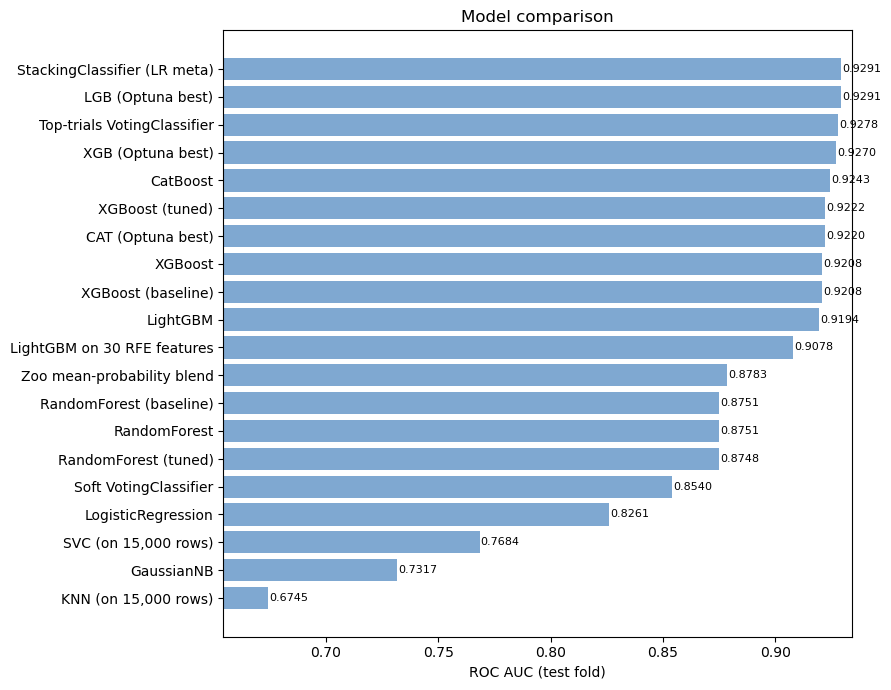

In [32]:
# visual comparison
fig, ax = plt.subplots(figsize=(9, max(3.5, 0.35 * len(lb))))
order = lb.sort_values("roc_auc")
ax.barh(order["model"], order["roc_auc"], color="#7fa8d1")
ax.set_xlim(max(0.5, order["roc_auc"].min() - 0.02), order["roc_auc"].max() + 0.005)
ax.set_xlabel("ROC AUC (test fold)")
ax.set_title("Model comparison")
for i, v in enumerate(order["roc_auc"]):
    ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

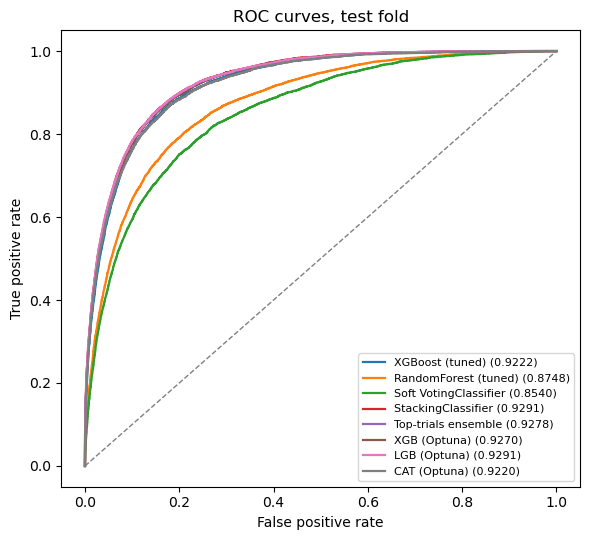

In [33]:
# ROC curves for the top few
top_n = 5
CANDIDATES = {}
if HAS_XGB:                    CANDIDATES["XGBoost (tuned)"] = lambda X: best_xgb.predict_proba(X)[:, 1]
CANDIDATES["RandomForest (tuned)"]  = lambda X: best_rf.predict_proba(X)[:, 1]
CANDIDATES["Soft VotingClassifier"] = lambda X: voting.predict_proba(X)[:, 1]
CANDIDATES["StackingClassifier"]    = lambda X: stack.predict_proba(X)[:, 1]
if top_ensemble is not None:
    CANDIDATES["Top-trials ensemble"] = lambda X: top_ensemble.predict_proba(X)[:, 1]
for k, m in BEST_MODELS.items():
    CANDIDATES[f"{k.upper()} (Optuna)"] = (lambda X, m=m: m.predict_proba(X)[:, 1])

fig, ax = plt.subplots(figsize=(6, 5.5))
for name, fn in CANDIDATES.items():
    p = fn(X_test_p)
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=1.6, label=f"{name} ({roc_auc_score(y_test, p):.4f})")
ax.plot([0, 1], [0, 1], ls="--", c="gray", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves, test fold"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 22. Pick a champion and calibrate it

The winner by AUC is selected automatically below; override `CHAMPION_NAME` if you want a
different one.

Then isotonic calibration. Every model above is trained on SMOTE'd data, which means its
predicted probabilities are wrong in a specific direction — the resampled base rate is 33%
while the real one is about 10.8%, so raw scores are inflated by roughly a factor of three.
Ranking is unaffected, so AUC does not move, but the Brier score and the reliability curve will
improve a lot, and any expected-loss calculation downstream is nonsense without this step.

Isotonic rather than Platt because you have the sample size for it.

In [34]:
# =====================================================================
# 22. CHAMPION + ISOTONIC CALIBRATION
# =====================================================================
CHAMPION_NAME = None   # e.g. "XGBoost (tuned)"; None = highest AUC among CANDIDATES

_scored = {n: roc_auc_score(y_test, fn(X_test_p)) for n, fn in CANDIDATES.items()}
if CHAMPION_NAME is None:
    CHAMPION_NAME = max(_scored, key=_scored.get)
print(f"Champion: {CHAMPION_NAME}  (test AUC {_scored[CHAMPION_NAME]:.4f})")

CHAMPION_MODEL = {
    "XGBoost (tuned)":        best_xgb,
    "RandomForest (tuned)":   best_rf,
    "Soft VotingClassifier":  voting,
    "StackingClassifier":     stack,
    "Top-trials ensemble":    top_ensemble,
    **{f"{k.upper()} (Optuna)": m for k, m in BEST_MODELS.items()},
}[CHAMPION_NAME]

def _prefit_calibrator(model, method="isotonic"):
    """cv='prefit' was removed in scikit-learn 1.6 in favour of FrozenEstimator."""
    try:
        from sklearn.frozen import FrozenEstimator          # sklearn >= 1.6
        return CalibratedClassifierCV(FrozenEstimator(model), method=method)
    except ImportError:
        return CalibratedClassifierCV(model, method=method, cv="prefit")

def _calibrate():
    cal = _prefit_calibrator(CHAMPION_MODEL, "isotonic")
    # calibrate on a slice of the test fold, hold the rest back for honest scoring
    idx = np.arange(len(y_test))
    cal_idx, hold_idx = train_test_split(idx, test_size=0.5, stratify=y_test,
                                         random_state=RANDOM_STATE)
    cal.fit(X_test_p[cal_idx], y_test.values[cal_idx])
    return {"model": cal, "cal_idx": cal_idx, "hold_idx": hold_idx}

_cal = checkpoint("22_calibrated.pkl", _calibrate)
CALIBRATED, hold_idx = _cal["model"], _cal["hold_idx"]

raw_hold = CHAMPION_MODEL.predict_proba(X_test_p[hold_idx])[:, 1]
cal_hold = CALIBRATED.predict_proba(X_test_p[hold_idx])[:, 1]
y_hold   = y_test.values[hold_idx]

print(f"\nactual default rate in holdout : {y_hold.mean():.4f}")
print(f"mean predicted, uncalibrated   : {raw_hold.mean():.4f}")
print(f"mean predicted, calibrated     : {cal_hold.mean():.4f}")
print(f"Brier uncalibrated {brier_score_loss(y_hold, raw_hold):.5f} "
      f"-> calibrated {brier_score_loss(y_hold, cal_hold):.5f}")
print(f"AUC   uncalibrated {roc_auc_score(y_hold, raw_hold):.4f} "
      f"-> calibrated {roc_auc_score(y_hold, cal_hold):.4f}   (should barely move)")

Champion: StackingClassifier  (test AUC 0.9291)
[checkpoint] computing 22_calibrated.pkl ...
[checkpoint] 22_calibrated.pkl finished in 1.9s
   saved -> artifacts\22_calibrated.pkl  (162.7 MB)

actual default rate in holdout : 0.1081
mean predicted, uncalibrated   : 0.3017
mean predicted, calibrated     : 0.1069
Brier uncalibrated 0.10147 -> calibrated 0.05652
AUC   uncalibrated 0.9284 -> calibrated 0.9280   (should barely move)


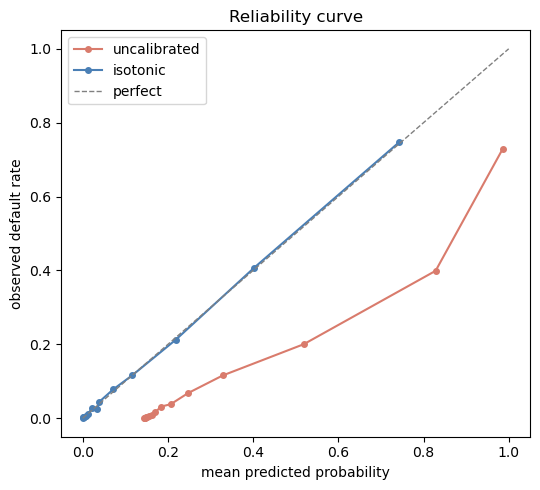

In [35]:
# reliability curve
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, p, c in [("uncalibrated", raw_hold, "#d97b6c"),
                    ("isotonic",     cal_hold, "#4a7fb5")]:
    ft, mp = calibration_curve(y_hold, p, n_bins=15, strategy="quantile")
    ax.plot(mp, ft, "o-", color=c, label=label, ms=4)
ax.plot([0, 1], [0, 1], "--", c="gray", lw=1, label="perfect")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed default rate")
ax.set_title("Reliability curve"); ax.legend()
plt.tight_layout(); plt.show()

## 23. Threshold selection

Three ways to cut, all reported so you can argue for one:

- **Youden's J** — maximises `TPR - FPR`. Statistically tidy, ignores that a missed default and
  a wasted collections call cost wildly different amounts.
- **Target recall** — the rule your original notebook used at 85%. Pick the recall the business
  will commit to, read off the precision you pay for it.
- **Max F1** — balanced, and rarely what a lender actually wants.

The gains table underneath is the artefact a risk team will ask for: sort by score, cut into
deciles, show how much of the bad book sits in the top few.

All of this is computed on the **holdout half** of the test fold — the half the isotonic
calibrator never saw. Reading a threshold off rows the calibrator was fitted on would bias it.

threshold/gains evaluated on 32,774 holdout rows (10.81% default rate)

Threshold comparison on the calibration holdout:

  Youden's J             thr=0.1185  P=0.401  R=0.856  F1=0.546  flagged=7,577 of 32,774
  recall >= 85%          thr=0.1171  P=0.401  R=0.856  F1=0.546  flagged=7,578 of 32,774
  max F1                 thr=0.3077  P=0.563  R=0.695  F1=0.622  flagged=4,373 of 32,774
  default 0.50           thr=0.5000  P=0.707  R=0.479  F1=0.571  flagged=2,399 of 32,774

Chosen: 0.1171


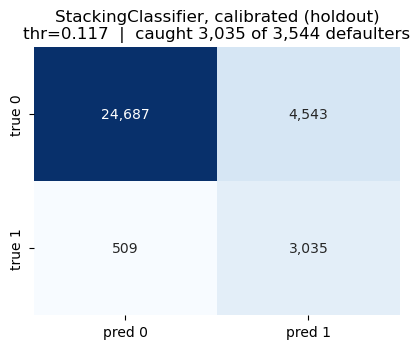

In [36]:
# =====================================================================
# 23. THRESHOLDS + GAINS TABLE
# =====================================================================
TARGET_RECALL = 0.85

# holdout half of the test fold — clean of the calibration fit
X_hold      = X_test_p[hold_idx]
champ_proba = CALIBRATED.predict_proba(X_hold)[:, 1]
y_eval      = y_test.values[hold_idx]
print(f"threshold/gains evaluated on {len(y_eval):,} holdout rows "
      f"({y_eval.mean():.2%} default rate)\n")

thr_youden = youden_threshold(y_eval, champ_proba)
thr_recall = threshold_for_recall(y_eval, champ_proba, TARGET_RECALL)
prec, rec, thr = precision_recall_curve(y_eval, champ_proba)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
thr_f1 = float(thr[int(np.argmax(f1s))])

print("Threshold comparison on the calibration holdout:\n")
for label, t in [("Youden's J", thr_youden),
                 (f"recall >= {TARGET_RECALL:.0%}", thr_recall),
                 ("max F1", thr_f1),
                 ("default 0.50", 0.5)]:
    r = evaluate(f"{CHAMPION_NAME} @ {label}", y_eval, champ_proba,
                 threshold=t, note="threshold", record=False, quiet=True)
    pred = (champ_proba >= t).astype(int)
    print(f"  {label:<22} thr={t:.4f}  P={r['precision']:.3f}  R={r['recall']:.3f}  "
          f"F1={r['f1']:.3f}  flagged={pred.sum():,} of {len(pred):,}")

CHOSEN_THRESHOLD = thr_recall
print(f"\nChosen: {CHOSEN_THRESHOLD:.4f}")
_ = plot_confusion(y_eval, champ_proba, CHOSEN_THRESHOLD,
                   f"{CHAMPION_NAME}, calibrated (holdout)")

In [37]:
# ---- decile gains table -------------------------------------------------
g = pd.DataFrame({"score": champ_proba, "actual": y_eval})
g["decile"] = pd.qcut(g["score"].rank(method="first", ascending=False),
                      10, labels=range(1, 11)).astype(int)

gains = (g.groupby("decile")
           .agg(accounts=("actual", "size"),
                defaults=("actual", "sum"),
                min_score=("score", "min"),
                max_score=("score", "max"))
           .reset_index())
gains["default_rate"] = gains["defaults"] / gains["accounts"]
gains["cum_defaults"] = gains["defaults"].cumsum()
gains["capture_rate"] = gains["cum_defaults"] / gains["defaults"].sum()
gains["lift"] = gains["default_rate"] / g["actual"].mean()

print(gains.to_string(index=False))
gains.to_csv(art("23_gains_table.csv"), index=False)
print(f"\nTop decile holds {gains.loc[0,'capture_rate']:.1%} of all defaults "
      f"at {gains.loc[0,'lift']:.2f}x lift.")
print(f"Top 3 deciles hold {gains.loc[2,'capture_rate']:.1%}.")

 decile  accounts  defaults  min_score  max_score  default_rate  cum_defaults  capture_rate   lift
      1      3278      2077     0.3641     1.0000        0.6336          2077        0.5861 5.8595
      2      3277       825     0.1370     0.3641        0.2518          2902        0.8188 2.3282
      3      3277       336     0.0637     0.1370        0.1025          3238        0.9137 0.9482
      4      3278       142     0.0346     0.0637        0.0433          3380        0.9537 0.4006
      5      3277        95     0.0237     0.0346        0.0290          3475        0.9805 0.2681
      6      3277        38     0.0071     0.0237        0.0116          3513        0.9913 0.1072
      7      3278        16     0.0020     0.0071        0.0049          3529        0.9958 0.0451
      8      3277        12     0.0017     0.0020        0.0037          3541        0.9992 0.0339
      9      3277         1     0.0002     0.0017        0.0003          3542        0.9994 0.0028
     10   

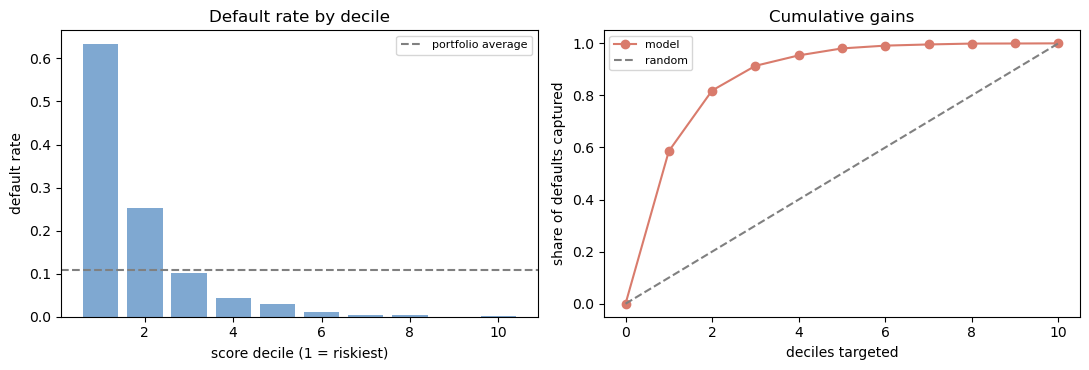

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(gains["decile"], gains["default_rate"], color="#7fa8d1")
ax[0].axhline(g["actual"].mean(), ls="--", c="gray", label="portfolio average")
ax[0].set_xlabel("score decile (1 = riskiest)"); ax[0].set_ylabel("default rate")
ax[0].set_title("Default rate by decile"); ax[0].legend(fontsize=8)

ax[1].plot([0] + gains["decile"].tolist(), [0] + gains["capture_rate"].tolist(),
           "o-", color="#d97b6c", label="model")
ax[1].plot([0, 10], [0, 1], "--", c="gray", label="random")
ax[1].set_xlabel("deciles targeted"); ax[1].set_ylabel("share of defaults captured")
ax[1].set_title("Cumulative gains"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 24. Score the prediction file

`HACKATHON_PREDICTION_DATA.CSV` goes through `apply_clean` with the *training* state — same
medians, same dummy columns, same clip bounds — then the same scaler and PCA, then the
calibrated champion. No rows are dropped.

Set `ID_COLUMN` if the auto-detection picks the wrong key.

In [39]:
# =====================================================================
# 24. PREDICTION FILE
# =====================================================================
ID_COLUMN = None   # set explicitly if the guess below is wrong

ID_CANDIDATES = ["CUSTOMER_ID", "CUST_ID", "ACCOUNT_NUMBER", "ACCT_NO", "ACCOUNT_NO",
                 "AGREEMENTID", "APPLICATION_ID", "LOAN_ID", "UCIC", "CIF", "ID"]

df_pred_raw = pd.read_csv(PRED_PATH, low_memory=False)
print(f"prediction file: {df_pred_raw.shape[0]:,} rows x {df_pred_raw.shape[1]} cols")

if ID_COLUMN is None:
    hit = [c for c in ID_CANDIDATES if c in df_pred_raw.columns]
    if hit:
        ID_COLUMN = hit[0]
    else:
        # fall back to a column that is not a model feature AND is unique per row,
        # so we do not accidentally grab something like PRODUCT_TYPE
        extra = [c for c in df_pred_raw.columns
                 if c not in clean_state["feature_columns"]
                 and c not in ONEHOT_COLS]
        unique = [c for c in extra if df_pred_raw[c].nunique() == len(df_pred_raw)]
        ID_COLUMN = unique[0] if unique else None
        if extra and not unique:
            print(f"   non-feature columns present but none unique: {extra[:6]}")

print(f"ID column: {ID_COLUMN!r}")
if ID_COLUMN is None:
    print("  [warn] no ID column found — the submission will use the row index")

prediction file: 191,693 rows x 138 cols
   non-feature columns present but none unique: ['NO_ENQ', 'FIRST_NPA_TENURE', 'CUST_NO_OF_TIMES_NPA', 'LATEST_NPA_TENURE', 'NO_YRS_NPA', 'LAST_1_YR_RG4']
ID column: None
  [warn] no ID column found — the submission will use the row index


In [40]:
X_pred = apply_clean(df_pred_raw, clean_state)
print(f"cleaned prediction features: {X_pred.shape}")
print(f"nulls after cleaning: {int(X_pred.isnull().sum().sum())}")

X_pred_p = to_model_space(X_pred)
pred_proba = CALIBRATED.predict_proba(X_pred_p)[:, 1]

submission = pd.DataFrame({
    (ID_COLUMN or "row_id"): (df_pred_raw[ID_COLUMN] if ID_COLUMN
                              else np.arange(len(df_pred_raw))),
    "predicted_probability": pred_proba,
    "predicted_flag": (pred_proba >= CHOSEN_THRESHOLD).astype(int),
})
submission.to_csv("submission_final.csv", index=False)

print(f"\nsaved -> submission_final.csv  ({len(submission):,} rows)")
print(f"flagged {submission['predicted_flag'].sum():,} accounts "
      f"({submission['predicted_flag'].mean():.2%}) at threshold {CHOSEN_THRESHOLD:.4f}")
print(f"mean predicted PD: {pred_proba.mean():.4f}  "
      f"(training prevalence was {y_all.mean():.4f})")
submission.head(10)

   [warn] 2 training features absent here, zero-filled: ['TIME_PERIOD_JAN25', 'TIME_PERIOD_NOV24']
cleaned prediction features: (191693, 136)
nulls after cleaning: 0

saved -> submission_final.csv  (191,693 rows)
flagged 39,139 accounts (20.42%) at threshold 0.1171
mean predicted PD: 0.0830  (training prevalence was 0.1081)


,row_id,predicted_probability,predicted_flag
0,0,0.0071,0
1,1,0.0020,0
2,2,0.0071,0
3,3,0.0123,0
4,4,0.0123,0
5,5,0.0637,0
6,6,0.0860,0
7,7,0.0637,0
8,8,0.0369,0
9,9,0.0123,0


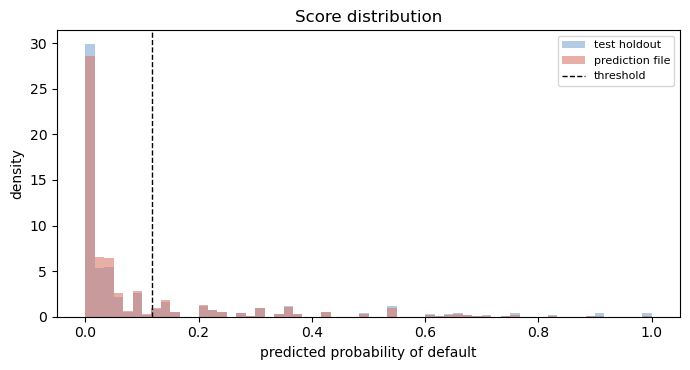

PSI(test fold -> prediction file) = 0.0523  [stable]


In [41]:
# score distribution — a sanity check on population drift between the two files
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(champ_proba, bins=60, alpha=0.6, density=True, label="test holdout", color="#7fa8d1")
ax.hist(pred_proba,  bins=60, alpha=0.6, density=True, label="prediction file", color="#d97b6c")
ax.axvline(CHOSEN_THRESHOLD, ls="--", c="black", lw=1, label="threshold")
ax.set_xlabel("predicted probability of default"); ax.set_ylabel("density")
ax.set_title("Score distribution"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# population stability index between the two score distributions
def psi(expected, actual, bins=10):
    edges = np.percentile(expected, np.linspace(0, 100, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual,   edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

val = psi(champ_proba, pred_proba)
verdict = ("stable" if val < 0.10 else
           "moderate shift — worth investigating" if val < 0.25 else
           "major shift — do not deploy without re-checking the feature distributions")
print(f"PSI(test fold -> prediction file) = {val:.4f}  [{verdict}]")

## 25. Save the deployable bundle

Everything needed to score a fresh file from raw CSV: the cleaning state, the scaler, the PCA
rotation, the calibrated model, the threshold, and the feature order. `score_new_file()` below
is the whole inference path in one function — useful if anyone asks you to demonstrate that the
model actually runs end to end.

In [42]:
# =====================================================================
# 25. FINAL BUNDLE
# =====================================================================
BUNDLE = {
    "clean_state":     clean_state,
    "scaler":          SCALER,
    "pca":             PCA_MODEL,
    "use_pca":         USE_PCA,
    "imputer":         IMPUTER,
    "champion_name":   CHAMPION_NAME,
    "champion_model":  CHAMPION_MODEL,
    "calibrated":      CALIBRATED,
    "threshold":       CHOSEN_THRESHOLD,
    "feature_columns": clean_state["feature_columns"],
    "model_features":  MODEL_FEATURE_NAMES,
    "test_auc":        float(roc_auc_score(y_eval, champ_proba)),
    "trained_on":      time.strftime("%Y-%m-%d %H:%M:%S"),
    "config": {
        "USE_PCA": USE_PCA, "PCA_VARIANCE": PCA_VARIANCE,
        "TEST_SIZE": TEST_SIZE, "UNDERSAMPLE_RATIO": UNDERSAMPLE_RATIO,
        "SMOTE_RATIO": SMOTE_RATIO, "RANDOM_STATE": RANDOM_STATE,
    },
}
save_art(BUNDLE, "99_pipeline_bundle.pkl")

lb.to_csv(art("99_final_leaderboard.csv"), index=False)
with open(art("99_run_summary.json"), "w") as f:
    json.dump({"champion": CHAMPION_NAME,
               "test_auc": BUNDLE["test_auc"],
               "threshold": CHOSEN_THRESHOLD,
               "n_features": len(MODEL_FEATURE_NAMES),
               "n_train": int(len(y_train)), "n_test": int(len(y_test)),
               "config": BUNDLE["config"]}, f, indent=2)

print(f"\nChampion : {CHAMPION_NAME}")
print(f"Test AUC : {BUNDLE['test_auc']:.4f}")
print(f"Threshold: {CHOSEN_THRESHOLD:.4f}")
print("\nArtifacts on disk:")
for f in sorted(os.listdir(ART_DIR)):
    print(f"  {f:<34} {os.path.getsize(art(f))/1e6:>8,.2f} MB")

   saved -> artifacts\99_pipeline_bundle.pkl  (162.5 MB)

Champion : StackingClassifier
Test AUC : 0.9280
Threshold: 0.1171

Artifacts on disk:
  01_clean_train.pkl                   351.35 MB
  02_split_meta.pkl                      1.51 MB
  04_transformers.pkl                    0.01 MB
  05_resampled.pkl                     286.31 MB
  10_xgb_base.pkl                        0.46 MB
  11_rf_base.pkl                       103.08 MB
  12_zoo_CatBoost.pkl                    1.13 MB
  12_zoo_GaussianNB.pkl                  0.01 MB
  12_zoo_KNN.pkl                        16.44 MB
  12_zoo_LightGBM.pkl                    0.37 MB
  12_zoo_LogisticRegression.pkl          0.00 MB
  12_zoo_RandomForest.pkl              103.08 MB
  12_zoo_SVC.pkl                         5.60 MB
  12_zoo_XGBoost.pkl                     0.46 MB
  13_rf_best.pkl                       148.55 MB
  13_rf_search.pkl                       0.00 MB
  13_xgb_best.pkl                        1.41 MB
  13_xgb_search.pkl    

In [43]:
# =====================================================================
# 26. ONE-CALL INFERENCE
# =====================================================================
def score_new_file(csv_path, bundle_path=None, id_column=None):
    """Raw CSV -> scored dataframe, using the saved bundle only."""
    b = joblib.load(bundle_path or art("99_pipeline_bundle.pkl"))
    raw = pd.read_csv(csv_path, low_memory=False)
    Xc = apply_clean(raw, b["clean_state"])
    Z = b["scaler"].transform(Xc)
    if b["pca"] is not None:
        Z = b["pca"].transform(Z)
    p = b["calibrated"].predict_proba(Z)[:, 1]
    out = pd.DataFrame({"predicted_probability": p,
                        "predicted_flag": (p >= b["threshold"]).astype(int)})
    if id_column and id_column in raw.columns:
        out.insert(0, id_column, raw[id_column].values)
    return out

# demo:
# scored = score_new_file(PRED_PATH, id_column=ID_COLUMN)
# scored.head()
print("score_new_file() ready")

score_new_file() ready


---
## What to check before you trust any of this

1. **Run it once with `USE_PCA = True` and once with `False`.** Keep both leaderboards. If the
   raw-feature version wins, drop PCA — it costs you interpretability for nothing.
2. **Compare the winner against your standalone LightGBM (AUC 0.9194).** If nothing here clears
   it by a real margin, that is the finding. A pipeline with more moving parts that lands in the
   same place tells you the signal is saturated, which is a more interesting thing to say than
   "I added six models."
3. **`train_test_split` is random, and your data is three monthly snapshots of what may be the
   same accounts.** If a customer appears in NOV24 and JAN25, random splitting puts one row in
   train and the other in test, and the test AUC is optimistic. Split by customer ID, or split
   by month with training on the earlier snapshots, and see how much AUC you lose. Whatever that
   gap is, it is the honest number.
4. **`LATEST_CR_DAYS` deserves a second look** before you defend the feature set — days since
   last credit event can be close to a restatement of the target depending on how the
   observation window was drawn.
